# Experimento *baseline* + variantes: U-Net frente a modelos fundacionales geoespaciales

**Avance semana 6 (informe de sprint).** Autores: Gerson Andre Garrido Mansilla y Renzo Elvis
Cerron Tome (Maestría en Ciencias con mención en IA, UNI).

**Pregunta.** ¿Un modelo fundacional geoespacial Transformer segmenta el agua de inundación en
Perú mejor que una CNN convencional cuando los tres se entrenan con las mismas etiquetas
peruanas?

**Relación con los avances anteriores.**
- Semana 4 (EDA, `notebooks/eda.ipynb`): fuga espacial controlada con bloques y *buffer*; agua
  minoritaria, por eso se usa el IoU de agua y no la exactitud; el suelo seco peruano difiere
  mucho del de Sen1Floods11.
- Semana 5 (ingeniería de características, `notebooks/feature_engineering.ipynb`): con
  etiquetas de Perú, las variables diseñadas no mejoran a un clasificador por píxel, y un umbral
  de MNDWI llega a 0.924. Ese umbral es aquí la referencia sin aprendizaje profundo.

**Qué hace este cuaderno.** Presenta resultados que ya existen en el proyecto. No entrena
modelos ni vuelve a evaluar ninguna partición de prueba. Las cifras se leen de
`notebooks/results/sprint6_results.csv`; cada fila indica de qué entrada de
`docs/EXPERIMENT_LOG.md` o de qué documento proviene.

## 1. Diseño experimental

| Rol | Modelo | Preentrenamiento | Bandas de entrada | Decodificador |
|---|---|---|---|---|
| ***Baseline*** | U-Net, codificador ResNet-34 | ImageNet | 13 bandas L1C | U-Net |
| **Variante 1** | TerraMind v1-B (Transformer, 103.0 M parámetros con decodificador) | Multimodal, observación de la Tierra | 13 bandas L1C | UNetDecoder [512, 256, 128, 64] |
| **Variante 2** | Prithvi-EO-2.0 300M (Transformer, 324.4 M parámetros con decodificador) | HLS (Landsat + Sentinel-2) | 6 bandas HLS: B02, B03, B04, B8A, B11, B12 | UNetDecoder [512, 256, 128, 64] |
| Referencia | Umbral de MNDWI = (B03 − B11)/(B03 + B11) | — | 2 bandas | — |

Parámetros medidos en `docs/feasibility.md`. Las configuraciones de TerraMind y Prithvi siguen
las oficiales de cada modelo para Sen1Floods11 (`configs/terramind_v1_base.yaml`,
`configs/prithvi_eo_v2_300.yaml`).

**Variables controladas.** Los tres modelos usan:
- los mismos datos: `peru-train` (753 recortes) para entrenar y `peru-dev` (174) para elegir la
  mejor época;
- la misma pérdida (Dice, píxeles ignorados con etiqueta −1);
- el mismo optimizador (AdamW) con ReduceLROnPlateau (factor 0.5, paciencia 5);
- el mismo criterio de parada: máximo 100 épocas y parada temprana con paciencia 20 sobre el IoU
  de agua en `peru-dev`;
- el mismo aumento de datos (D4: rotaciones y reflejos);
- la normalización oficial de cada modelo.

**Lo que cambia entre filas** es la arquitectura y su preentrenamiento, con los hiperparámetros
oficiales de cada uno:
- tasa de aprendizaje: U-Net 1e-4, TerraMind 2e-5, Prithvi 1e-4;
- lote: 8, 8 y 4.

**Protocolo.**
- 3 semillas por modelo (0, 1, 2). Se reporta la media ± la desviación estándar muestral.
- Entrenamiento en RunPod (RTX 4090, precisión mixta de 16 bits), entre 22 y 35 minutos por
  corrida.
- La selección se hace solo en `peru-dev`.
- `peru-test` (172 recortes, bloques espaciales no vistos) y `peru-2017-test` (otro evento,
  Copernicus EMS 2017) se evaluaron **una sola vez**, el 2026-10-16, desde configuraciones
  congeladas con el hash de cada checkpoint (`configs/frozen.yaml`).

**Métrica principal.** IoU de agua agrupado sobre todos los píxeles etiquetados de la
partición:

$$\mathrm{IoU} = \frac{TP}{TP + FP + FN}.$$

Se reportan también el mIoU (media del IoU de agua y de no agua), la precisión, el recall y el
IoU tolerante a bordes, que excluye los píxeles a ≤ 1 px del borde de la etiqueta.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts" / "figures"))
try:
    import style; style.apply(); COLOR = style.MODEL
except Exception as e:  # el estilo de las figuras de la tesis es opcional
    print("estilo de tesis no disponible:", e); COLOR = {}
%matplotlib inline
pd.set_option("display.precision", 4)

FIGS = REPO / "docs" / "figs" / "sprint6"; FIGS.mkdir(parents=True, exist_ok=True)
KEY = {"U-Net (ResNet-34)": "unet", "TerraMind v1-B": "terramind_v1_base", "Prithvi-EO-2.0 300M": "prithvi_eo_v2_300"}
ORDER = list(KEY)
LABEL = {"U-Net (ResNet-34)": "Baseline: U-Net", "TerraMind v1-B": "Variante 1: TerraMind v1-B",
         "Prithvi-EO-2.0 300M": "Variante 2: Prithvi-EO-2.0"}

r = pd.read_csv(REPO / "notebooks" / "results" / "sprint6_results.csv", dtype={"seed": str})
bad = r[r.source.isna() | (r.source.str.strip() == "")]
if len(bad):
    raise ValueError(f"filas sin fuente: {bad.index.tolist()}")
assert not r.split.isin(["peru-test", "peru-2017-test"]).any() or r.source[r.split.isin(["peru-test", "peru-2017-test"])].str.startswith("docs/phaseD_test.md").all()

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")

print(len(r), "valores con fuente;", r.source.nunique(), "documentos de origen distintos")

67 valores con fuente; 13 documentos de origen distintos


## 2. Resultados en `peru-dev` (partición de selección)

Cada modelo se entrenó con 3 semillas. La media y la desviación estándar se recalculan aquí a
partir de las tres semillas y se comparan con las del registro.

In [2]:
dev = r[(r.split == "peru-dev") & (r.metric == "iou_water") & r.seed.isin(["0", "1", "2"])]
seeds = dev.pivot(index="model", columns="seed", values="value").loc[ORDER]
logged = r[(r.split == "peru-dev") & (r.metric.isin(["iou_water", "miou"])) & r.seed.isin(["mean", "std"])]
logged = logged.pivot_table(index="model", columns=["metric", "seed"], values="value").loc[ORDER]
epochs = r[(r.metric == "best_epoch")].pivot(index="model", columns="seed", values="value").loc[ORDER]

t = pd.DataFrame({
    "rol": [LABEL[m].split(":")[0] for m in ORDER],
    "semilla 0": seeds["0"], "semilla 1": seeds["1"], "semilla 2": seeds["2"],
    "IoU media": seeds.mean(axis=1), "IoU de (muestral)": seeds.std(axis=1, ddof=1),
    "mIoU media": logged[("miou", "mean")], "mIoU de": logged[("miou", "std")],
    "mejor época (s0/s1/s2)": epochs.astype(int).astype(str).agg("/".join, axis=1),
})
t["Δ IoU vs baseline"] = t["IoU media"] - t.loc["U-Net (ResNet-34)", "IoU media"]
check = (t["IoU media"].round(4) == logged[("iou_water", "mean")]) & (t["IoU de (muestral)"].round(4) == logged[("iou_water", "std")])
print("media y de recalculadas = registro (4 decimales):", bool(check.all()))
t.to_csv(FIGS / "tabla_dev.csv")
display(t.round(4))

media y de recalculadas = registro (4 decimales): True


,rol,semilla 0,semilla 1,semilla 2,IoU media,IoU de (muestral),mIoU media,mIoU de,mejor época (s0/s1/s2),Δ IoU vs baseline
model,,,,,,,,,,
U-Net (ResNet-34),Baseline,0.9397,0.9434,0.9414,0.9415,0.0019,0.9665,0.0011,51/98/63,0.0000
TerraMind v1-B,Variante 1,0.9275,0.9237,0.9283,0.9265,0.0025,0.9579,0.0014,92/93/88,-0.0150
Prithvi-EO-2.0 300M,Variante 2,0.9212,0.9225,0.9217,0.9218,0.0007,0.9552,0.0004,48/51/44,-0.0197


**Referencias sin aprendizaje profundo** (umbral de MNDWI en `peru-dev`). La fila de
`peru-train` viene del experimento de la semana 5, evaluado sobre 1/4 de los píxeles de dev;
las demás, sobre todos los píxeles.

In [3]:
ref = r[(r.role == "reference")][["model", "method", "train_data", "value", "source"]]
ref["method"] = ref.method.map({"fixed threshold (no training)": "fijo, sin datos",
                                "Otsu threshold on unlabelled peru-train images": "Otsu sobre imágenes de peru-train, sin etiquetas",
                                "threshold fitted on peru-train labels": "ajustado con etiquetas de peru-train",
                                "threshold tuned on peru-dev labels": "ajustado con etiquetas de peru-dev (oráculo)"})
ref["train_data"] = ref.train_data.replace({"none": "ninguna"})
ref = ref.rename(columns={"model": "regla", "method": "cómo se fija el umbral", "train_data": "etiquetas usadas", "value": "IoU de agua", "source": "fuente"})
ref.to_csv(FIGS / "tabla_referencias.csv", index=False)
display(ref.reset_index(drop=True))

,regla,cómo se fija el umbral,etiquetas usadas,IoU de agua,fuente
0,MNDWI > 0,"fijo, sin datos",ninguna,0.4858,docs/phaseD_dev.md dev table (MNDWI > 0)
1,MNDWI > Otsu,"Otsu sobre imágenes de peru-train, sin etiquetas",ninguna,0.5718,docs/phaseD_dev.md dev table (MNDWI > Otsu thr...
2,MNDWI > 0.28,ajustado con etiquetas de peru-train,peru-train,0.9237,docs/METHODS_NOTES.md 2026-10-16 Feature engin...
3,MNDWI > 0.27 (oracle),ajustado con etiquetas de peru-dev (oráculo),peru-dev,0.9251,docs/phaseD_dev.md dev table (MNDWI > +0.27 or...


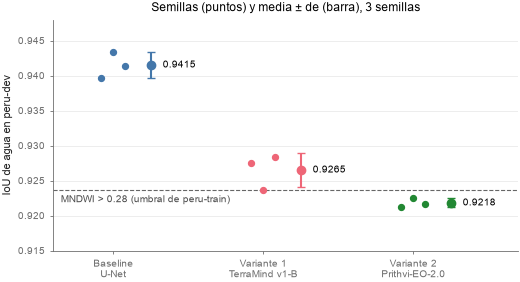

In [4]:
fig, ax = plt.subplots(figsize=(6.0, 3.0))
for i, m in enumerate(ORDER):
    v = seeds.loc[m].values; c = COLOR.get(KEY[m], f"C{i}")
    ax.scatter(np.full(3, i) + np.array([-0.08, 0, 0.08]), v, color=c, s=18, zorder=3, label=None)
    ax.errorbar(i + 0.25, v.mean(), yerr=v.std(ddof=1), fmt="o", color=c, ms=6, capsize=3, zorder=3)
    ax.text(i + 0.33, v.mean(), f"{v.mean():.4f}", va="center", fontsize=7)
mndwi = ref.set_index("regla")["IoU de agua"]
ax.axhline(mndwi["MNDWI > 0.28"], ls="--", lw=0.8, color="0.4")
ax.text(-0.35, mndwi["MNDWI > 0.28"] - 0.0018, "MNDWI > 0.28 (umbral de peru-train)", fontsize=7, ha="left", color="0.3")
ax.set_xticks(range(3), [LABEL[m].replace(": ", "\n") for m in ORDER])
ax.set_xlim(-0.4, 2.7); ax.set_ylim(0.915, 0.948)
ax.set_ylabel("IoU de agua en peru-dev"); ax.grid(axis="y")
ax.set_title("Semillas (puntos) y media ± de (barra), 3 semillas")
save(fig, "fig_dev_semillas"); plt.show()

**Lectura de la tabla de dev.**
- El *baseline* U-Net obtiene el mayor IoU (0.9415 ± 0.0019), seguido de TerraMind
  (0.9265 ± 0.0025) y Prithvi (0.9218 ± 0.0007). Las diferencias (−0.015 y −0.020) son varias
  veces mayores que la variación entre semillas.
- Las tres semillas de TerraMind eligieron épocas cercanas al tope de 100 (92, 93 y 88). Para
  descartar un infraentrenamiento se repitió la semilla 0 con un tope de 200 épocas. La parada
  temprana la detuvo en la época 98, con un mejor IoU de 0.9270 en la época 77 (frente a 0.9275
  con el tope de 100). El tope no limitaba a TerraMind (`docs/EXPERIMENT_LOG.md`, 2026-10-14).
- El umbral de MNDWI fijado con etiquetas de `peru-train` ya llega a 0.9237. Solo la U-Net lo
  supera con claridad (+0.018). TerraMind queda prácticamente igual (+0.003) y Prithvi por debajo
  (−0.002). El umbral se evaluó sobre 1/4 de los píxeles de dev y los modelos sobre todos, así
  que la comparación es aproximada. En Perú 2023 la separación agua/suelo es casi un umbral
  espectral (semana 5).

**¿Dónde está la ventaja de la U-Net?** El análisis de bordes (`docs/METHODS_NOTES.md`,
2026-10-14) recalcula el IoU excluyendo los píxeles a ≤ 1 px del borde de la etiqueta. Las
etiquetas de UNOSAT son polígonos rasterizados, menos fiables justo en los bordes.

In [5]:
edge = r[r.metric.str.startswith("unet_minus_model")].pivot(index="model", columns="metric", values="value")
edge = edge.rename(columns={"unet_minus_model_plain_pts": "U-Net − modelo, IoU normal (puntos)",
                            "unet_minus_model_excl1px_pts": "U-Net − modelo, sin borde ≤ 1 px (puntos)"})
edge.to_csv(FIGS / "tabla_bordes.csv"); display(edge)

metric,"U-Net − modelo, sin borde ≤ 1 px (puntos)","U-Net − modelo, IoU normal (puntos)"
model,,
Prithvi-EO-2.0 300M,0.28,1.97
TerraMind v1-B,0.40,1.50


El 73 % de la ventaja de la U-Net sobre TerraMind y el 86 % de su ventaja sobre Prithvi están
en la franja de 1 píxel del borde de la etiqueta. Fuera de ella, la ventaja es de 0.3 a 0.4 puntos
de IoU: pequeña, pero estable entre 1 y 3 px (`docs/METHODS_NOTES.md`). La U-Net dibuja bordes más
finos a 10 m; los Transformer procesan la imagen en parches y recuperan la resolución en el
decodificador.

## 3. Evaluación única en las particiones de prueba

Estas cifras vienen de la evaluación única del 2026-10-16 (`docs/phaseD_test.md`). El IC del
95 % es un *bootstrap* por recortes de la media de las semillas.

In [6]:
te = r[r.split == "peru-test"].pivot_table(index="model", columns=["metric", "seed"], values="value").loc[ORDER]
devm = seeds.mean(axis=1)
tt = pd.DataFrame({
    "rol": [LABEL[m].split(":")[0] for m in ORDER],
    "IoU media": te[("iou_water", "mean")], "IoU de": te[("iou_water", "std")],
    "IC 95 % inf.": te[("iou_water", "ci_low")], "IC 95 % sup.": te[("iou_water", "ci_high")],
    "IoU tolerante": te[("iou_tolerant", "mean")], "precisión": te[("precision", "mean")], "recall": te[("recall", "mean")],
    "IoU en dev": devm, "caída dev → prueba": devm - te[("iou_water", "mean")],
})
tt.to_csv(FIGS / "tabla_prueba.csv"); display(tt.round(4))

y17 = r[r.split == "peru-2017-test"].pivot(index="model", columns="metric", values="value").loc[ORDER]
y17 = y17.rename(columns={"iou_water_101": "IoU, 101 recortes (principal)", "iou_water_204": "IoU, 204 recortes"})
y17.to_csv(FIGS / "tabla_2017.csv"); display(y17)

,rol,IoU media,IoU de,IC 95 % inf.,IC 95 % sup.,IoU tolerante,precisión,recall,IoU en dev,caída dev → prueba
model,,,,,,,,,,
U-Net (ResNet-34),Baseline,0.8280,0.0023,0.732,0.895,0.861,0.966,0.853,0.9415,0.1135
TerraMind v1-B,Variante 1,0.8149,0.0023,0.718,0.885,0.852,0.960,0.843,0.9265,0.1116
Prithvi-EO-2.0 300M,Variante 2,0.8244,0.0066,0.731,0.890,0.866,0.966,0.850,0.9218,0.0974


metric,"IoU, 101 recortes (principal)","IoU, 204 recortes"
model,,
U-Net (ResNet-34),0.878,0.916
TerraMind v1-B,0.892,0.919
Prithvi-EO-2.0 300M,0.878,0.912


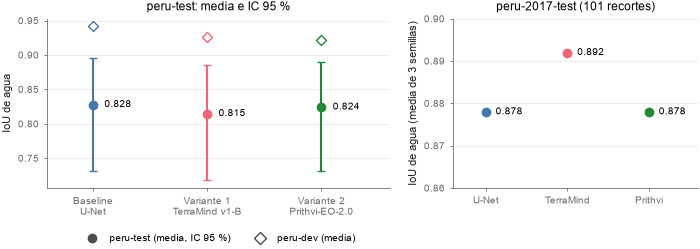

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axs[0]
for i, m in enumerate(ORDER):
    c = COLOR.get(KEY[m], f"C{i}"); row = tt.loc[m]
    ax.errorbar(i, row["IoU media"], yerr=[[row["IoU media"] - row["IC 95 % inf."]], [row["IC 95 % sup."] - row["IoU media"]]],
                fmt="o", color=c, capsize=3, ms=6)
    ax.scatter(i, row["IoU en dev"], marker="D", facecolor="white", edgecolor=c, s=26, zorder=3, label="peru-dev" if i == 0 else None)
    ax.text(i + 0.1, row["IoU media"], f"{row['IoU media']:.3f}", va="center", fontsize=7)
ax.set_xticks(range(3), [LABEL[m].replace(": ", "\n") for m in ORDER]); ax.set_xlim(-0.4, 2.6)
ax.set_ylabel("IoU de agua"); ax.set_title("peru-test: media e IC 95 %"); ax.grid(axis="y")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color="0.3", label="peru-test (media, IC 95 %)"),
                   plt.Line2D([], [], marker="D", ls="", mfc="white", mec="0.3", label="peru-dev (media)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax = axs[1]
x = np.arange(3)
for i, m in enumerate(ORDER):
    v = y17.loc[m, "IoU, 101 recortes (principal)"]
    ax.scatter(i, v, color=COLOR.get(KEY[m], f"C{i}"), s=36, zorder=3)
    ax.text(i + 0.12, v, f"{v:.3f}", va="center", fontsize=7)
ax.set_xticks(x, ["U-Net", "TerraMind", "Prithvi"]); ax.set_xlim(-0.4, 2.6); ax.set_ylim(0.86, 0.90)
ax.set_ylabel("IoU de agua (media de 3 semillas)")
ax.set_title("peru-2017-test (101 recortes)"); ax.grid(axis="y")
plt.tight_layout(); save(fig, "fig_prueba"); plt.show()

**Lectura de la prueba.**
- **`peru-test` (2023, bloques no vistos):** el orden de dev se mantiene en las medias (U-Net
  0.828, Prithvi 0.824, TerraMind 0.815), pero los IC del 95 % se solapan casi por completo. No
  se calcularon diferencias pareadas entre estos tres modelos, así que **no se puede afirmar que
  uno supere a otro en prueba**.
- Los tres caen entre 0.097 y 0.114 de dev a prueba. La caída es parecida en los tres, y el
  recall baja de 0.97 a 0.85 en la U-Net (`docs/phaseD_test.md`). Los bloques de prueba son más difíciles
  o están etiquetados de otra forma; no es un fallo de un modelo concreto.
- La precisión es alta en los tres (0.96–0.97). El error dominante en prueba es la omisión de
  agua (recall 0.84–0.85).
- **`peru-2017-test` (otro evento):** TerraMind queda primero (0.892, frente a 0.878 de los
  otros dos). Las etiquetas de 2017 solo definen suelo seco donde MNDWI ≤ 0, así que esta
  partición mide sobre todo el recall del agua clara. Es una prueba de generalización a otro
  evento, no una réplica de 2023.

## 4. Verificación con los resultados originales (si están disponibles)

`outputs/` no forma parte del repositorio. Si está presente, se comparan los IoU por semilla de
la tabla con los de `outputs/phaseD/dev_table_runs.csv` (régimen `peru`), calculados desde los
logits guardados.

In [8]:
src = REPO / "outputs" / "phaseD" / "dev_table_runs.csv"
if src.exists():
    o = pd.read_csv(src); o = o[o.regime == "peru"]
    o["seed"] = o.seed.str.replace("seed", ""); o["model"] = o.model.map({v: k for k, v in KEY.items()})
    m = dev.merge(o[["model", "seed", "iou"]], on=["model", "seed"], how="left")
    m["dif"] = (m.value - m.iou).abs()
    display(m[["model", "seed", "value", "iou", "dif"]])
    print("diferencias > 1e-4:", int((m.dif > 1e-4).sum()), "| filas sin par:", int(m.iou.isna().sum()))
else:
    print("outputs/ no está en esta máquina: se usa solo la tabla con fuentes (notebooks/results/sprint6_results.csv).")

outputs/ no está en esta máquina: se usa solo la tabla con fuentes (notebooks/results/sprint6_results.csv).


## 5. Conclusiones

1. **Con etiquetas de Perú, el *baseline* U-Net no es superado.** En `peru-dev` gana por
   0.015–0.020 de IoU. En `peru-test` las tres medias quedan a menos de 0.014 entre sí, con IC
   solapados.
2. **La ventaja de la U-Net está sobre todo en los bordes de la etiqueta.** Fuera de la franja de
   1 px, la diferencia baja a 0.3–0.4 puntos. Parte del ranking en IoU normal depende de cómo cada
   modelo dibuja bordes que la propia etiqueta no fija con precisión.
3. **El umbral de MNDWI es una referencia exigente.** Llega a 0.924 en dev: solo la U-Net lo
   supera con claridad, y en este evento el margen para cualquier modelo aprendido es pequeño.
4. **La generalización a otro evento cambia el orden.** En 2017 TerraMind queda primero, pero esa
   partición mide solo el recall del agua clara.
5. **Implicación para la tesis.** El valor de los modelos fundacionales no está en el escenario con
   etiquetas del mismo evento. Hay que estudiar la transferencia sin etiquetas peruanas (fase D),
   donde el cambio de dominio del suelo seco es el problema principal (semanas 4 y 5).

**Limitaciones.**
- Una sola partición espacial y 3 semillas: la desviación estándar solo mide la variación entre
  semillas.
- En prueba solo están en el registro los valores agregados (media, de, IC), no los de cada semilla.
- No hay diferencias pareadas entre los tres modelos en prueba.
- El umbral de MNDWI se comparó sobre 1/4 de los píxeles de dev; los modelos, sobre todos.
- Los hiperparámetros son los oficiales de cada modelo, no ajustados para Perú.